In [1]:
import numpy as np
import pandas as pd

from black_scholes import bsm_price
from hedging_engine import run_delta_hedging
from processes import simulate_gbm, simulate_merton_jump_diffusion
from metrics import summarize_pnl
from plots.PnL_plots import plot_pnl

In [2]:
bsm_price(S=100, K=100, T=1, sigma=0.2, r=0.05)   

np.float64(99.99546000702375)

In [3]:
seed = 42
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20
N = 1008

In [4]:
S = simulate_gbm(S0=100.0, mu=0.08, sigma=sigma, T=T, N=N, M=10_000, seed=12)
N = S.shape[1] - 1

In [5]:
seeds = [1, 5, 7, 42, 144, 44, 424, 34]

for i in seeds:
    S = simulate_gbm(S0=100.0, mu=0.08, sigma=sigma, T=T, N=N, M=10_000, seed=i)
    N = S.shape[1] - 1
    pnl = run_delta_hedging(S=S, K=K, T=T, sigma=sigma, r=r)
    print(f"seed: {i}, mean p&l: {np.mean(pnl)}, standard deviation of p&l: {np.std(pnl)}")

seed: 1, mean p&l: 0.006136876866502111, standard deviation of p&l: 0.9745902006253252
seed: 5, mean p&l: -9.481261801565069e-05, standard deviation of p&l: 0.967638651423856
seed: 7, mean p&l: -0.003246532009812179, standard deviation of p&l: 0.9746946305960379
seed: 42, mean p&l: 0.010635641939823491, standard deviation of p&l: 0.9817954196871079
seed: 144, mean p&l: -0.0026945961760087016, standard deviation of p&l: 0.9696296303675741
seed: 44, mean p&l: -0.015481544318907798, standard deviation of p&l: 0.9902358234687008
seed: 424, mean p&l: -0.008251183303726052, standard deviation of p&l: 0.9780926455701846
seed: 34, mean p&l: 0.0009210648753088819, standard deviation of p&l: 0.962680303687042


In [6]:
pnl = run_delta_hedging(S=S, K=K, T=T, sigma=sigma, r=r)
print(pnl)

[ 0.04690472 -0.42663246  0.16423593 ...  0.80375083  0.14591141
 -0.57480747]


In [7]:
pnl = run_delta_hedging(S=S, K=K, T=T, sigma=sigma, r=r)
summarize_pnl(pnl)

{'mean p&l': 0.0009210648753088819,
 'std of p&l': 0.962680303687042,
 'median of p&l': 0.009499544424794145,
 'skewness': -0.1228674630003735,
 'excess kurtosis': 1.3770305522903286,
 'VaR_95': -1.5976839765520285,
 'CVaR_95': -2.1759432914949954}

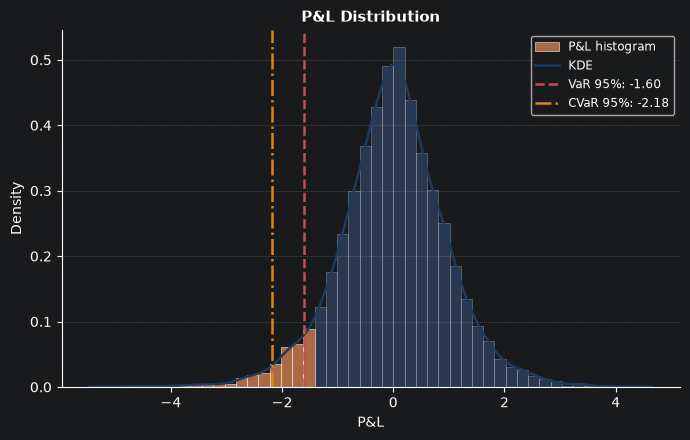

<Axes: title={'center': 'P&L Distribution'}, xlabel='P&L', ylabel='Density'>

In [23]:
plot_pnl(pnl)

In [19]:
params_common = dict(S0=100.0, mu=0.08, sigma=0.20, T=1.0, M=5000, N=252, seed=42)
hedge_params = dict(K=100.0, T=1.0, sigma=0.20, r=0.05)

S_gbm = simulate_gbm(**params_common)
S_merton_mod = simulate_merton_jump_diffusion(
    **params_common, lam=3.0, mu_j=-0.02, delta=0.05
)
S_merton_stress = simulate_merton_jump_diffusion(
    **params_common, lam=5.0, mu_j=-0.05, delta=0.10
)

pnl_gbm = run_delta_hedging(S=S_gbm, **hedge_params)
pnl_merton_mod = run_delta_hedging(S=S_merton_mod, **hedge_params)
pnl_merton_stress = run_delta_hedging(S=S_merton_stress, **hedge_params)

df_compare = pd.DataFrame({
    "GBM": summarize_pnl(pnl_gbm),
    "Merton (moderate)": summarize_pnl(pnl_merton_mod),
    "Merton (stress)": summarize_pnl(pnl_merton_stress),
}).T

print(df_compare)

                   mean p&l  std of p&l  median of p&l  skewness  \
GBM                0.039284    1.901449       0.026974 -0.374820   
Merton (moderate) -0.772739    2.308646      -0.573471 -0.971489   
Merton (stress)   -4.614845    4.767910      -3.405802 -1.513576   

                   excess kurtosis     VaR_95    CVaR_95  
GBM                       1.889581  -3.073940  -4.363435  
Merton (moderate)         3.037392  -4.886323  -6.884212  
Merton (stress)           3.527384 -14.017198 -18.121954  


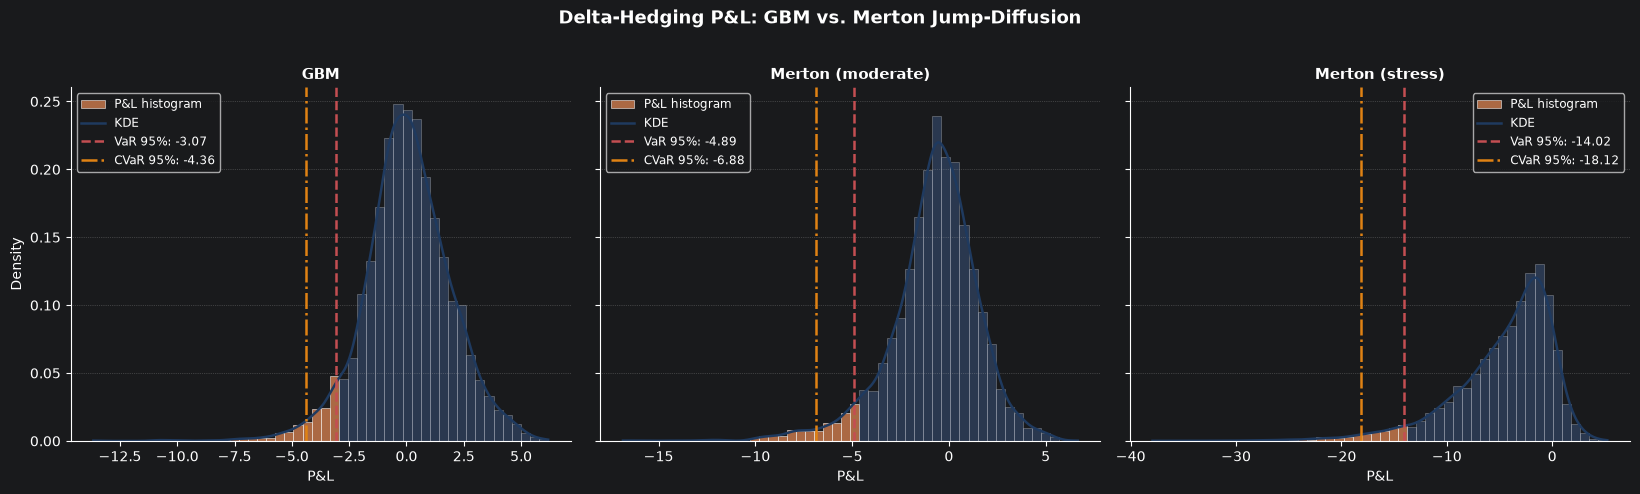

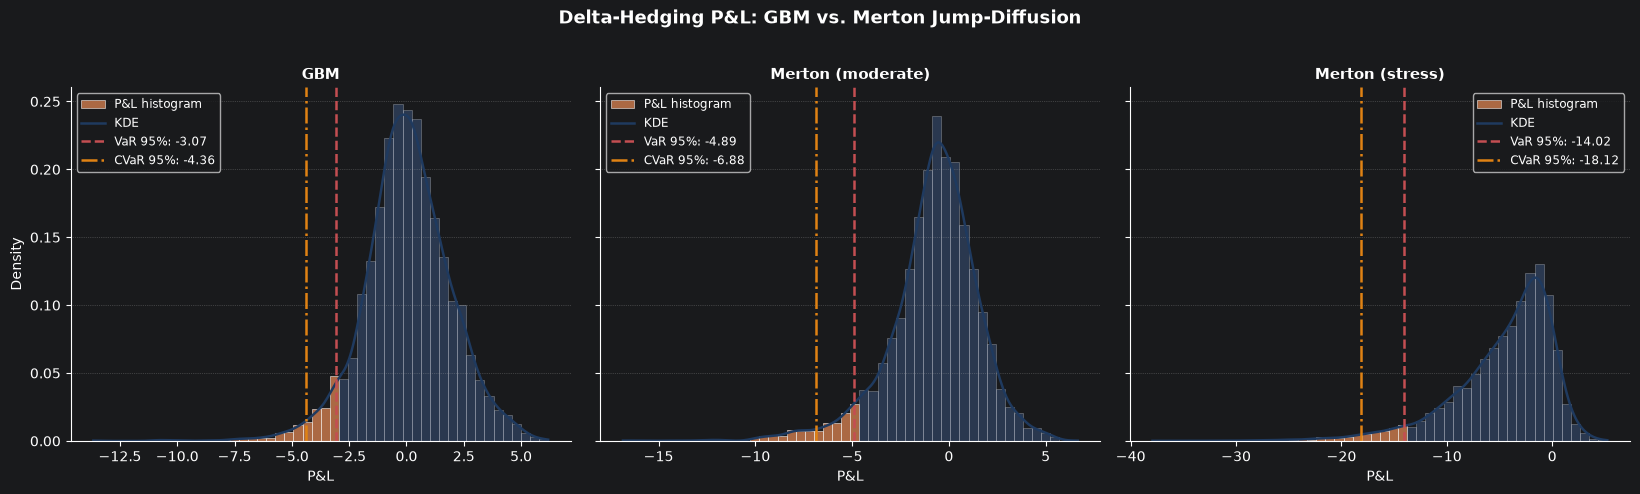

In [9]:
from plots.PnL_plots import plot_pnl_comparison

plot_pnl_comparison({
    "GBM": pnl_gbm,
    "Merton (moderate)": pnl_merton_mod,
    "Merton (stress)": pnl_merton_stress,
})

In [ ]:
# Compare 3 different hedging specifications:
# - monthly rebalance, no transactional cost
# - daily rebalance, no transactional cost
# - daily rebalance, transactional cost active

In [22]:
def summarize_pnl(pnl: pd.Series) -> pd.Series:
    s = pd.Series(pnl)
    return pd.Series({
        "mean": s.mean(),
        "std": s.std(ddof=1),
        "var_95": s.quantile(0.05),
        "var_99": s.quantile(0.01),
    })


def compare_rebalance_and_costs(
    paths_dict: dict,
    hedge_base_params: dict,
    cost_value: float = 0.005,
):
    configs = {
        "monthly_no_cost": {"rebalance_every": 21, "cost": 0.0},
        "daily_no_cost": {"rebalance_every": 1, "cost": 0.0},
        "daily_with_cost": {"rebalance_every": 1, "cost": cost_value},
    }

    results = {}
    for cfg_name, cfg_params in configs.items():
        rows = {}
        for regime_name, S in paths_dict.items():
            pnl = run_delta_hedging(
                S=S,
                **hedge_base_params,
                **cfg_params,
            )
            rows[regime_name] = summarize_pnl(pnl)
        results[cfg_name] = pd.DataFrame(rows).T

    df_summary = pd.concat(results, axis=1)
    diff_rebalance_only = results["daily_no_cost"] - results["monthly_no_cost"]
    diff_cost_only = results["daily_with_cost"] - results["daily_no_cost"]

    return df_summary, diff_rebalance_only, diff_cost_only


paths = {
    "GBM": S_gbm,
    "Merton (moderate)": S_merton_mod,
    "Merton (stress)": S_merton_stress,
}
hedge_base = dict(K=100.0, T=1.0, sigma=0.20, r=0.05)

df_all, diff_freq, diff_cost = compare_rebalance_and_costs(
    paths_dict=paths,
    hedge_base_params=hedge_base,
    cost_value=0.005,
)

print("=== Every Specification ===")
print(df_all)
print("\n=== The impact of change from rebalancing every 21 days to daily (no transactional costs) ===")
print(diff_freq)
print("\n=== The impact of transactional costs (daily rebalancing) ===")
print(diff_cost)

=== Every Variant ===
                  monthly_no_cost                                  \
                             mean       std     var_95     var_99   
GBM                      0.039284  1.901639  -3.073940  -4.995352   
Merton (moderate)       -0.772739  2.308877  -4.886323  -8.121774   
Merton (stress)         -4.614845  4.768386 -14.017198 -20.747552   

                  daily_no_cost                                  \
                           mean       std     var_95     var_99   
GBM                    0.003474  0.439603  -0.704384  -1.204241   
Merton (moderate)     -0.796168  1.075642  -2.799978  -4.750375   
Merton (stress)       -4.684612  4.175717 -12.579325 -18.481958   

                  daily_with_cost                                  
                             mean       std     var_95     var_99  
GBM                     -3.178968  1.027315  -5.019212  -5.830401  
Merton (moderate)       -3.948113  1.603407  -6.900976  -8.898696  
Merton (stress)         

In [ ]:
# Compare how volatility misspecification impacts the pnl

In [25]:
def compare_volatility(
    paths_dict: dict,
    hedge_base_params: dict,
    model_vol: float = 0.20,
    misspecified_vol: float = 0.30,
):
    base_params = {k: v for k, v in hedge_base_params.items() if k != "sigma"}

    configs = {
        "correct volatility": {"sigma": model_vol, "sigma_price": model_vol},
        "misspecified volatility": {"sigma": misspecified_vol, "sigma_price": model_vol},
    }

    results = {}
    for cfg_name, cfg_params in configs.items():
        rows = {}
        for regime_name, S in paths_dict.items():
            pnl = run_delta_hedging(
                S=S,
                **base_params,
                **cfg_params,
            )
            rows[regime_name] = summarize_pnl(pnl)
        results[cfg_name] = pd.DataFrame(rows).T

    df_summary = pd.concat(results, axis=1)
    diff_misspecified_volatility = (
        results["misspecified volatility"] - results["correct volatility"]
    )

    return df_summary, diff_misspecified_volatility


paths = {
    "GBM": S_gbm,
    "Merton (moderate)": S_merton_mod,
    "Merton (stress)": S_merton_stress,
}
hedge_base = dict(K=100.0, T=1.0, r=0.05)

df_all, diff_vol = compare_volatility(
    paths_dict=paths,
    hedge_base_params=hedge_base,
    model_vol=0.20,
    misspecified_vol=0.30,
)

print("=== Every Specification ===")
print(df_all)
print("\n=== The impact of misspecified volatility ===")
print(diff_vol)

=== Every Specification ===
                  correct volatility                                  \
                                mean       std     var_95     var_99   
GBM                         0.039284  1.901639  -3.073940  -4.995352   
Merton (moderate)          -0.772739  2.308877  -4.886323  -8.121774   
Merton (stress)            -4.614845  4.768386 -14.017198 -20.747552   

                  misspecified volatility                                 
                                     mean       std    var_95     var_99  
GBM                              3.979798  2.277490  0.532281  -0.728476  
Merton (moderate)                3.160664  2.467411 -0.550536  -2.784587  
Merton (stress)                 -0.640696  4.121309 -7.992930 -13.333461  

=== The impact of misspecified volatility ===
                       mean       std    var_95    var_99
GBM                3.940513  0.375851  3.606221  4.266876
Merton (moderate)  3.933402  0.158534  4.335787  5.337188
Merton (stress)